### Task 3 – Transfer Learning

In [1]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

data = np.load("cifar10_preprocessed.npz")

x_train = data["x_train"]
y_train = data["y_train"]

x_val = data["x_val"]
y_val = data["y_val"]

x_test = data["x_test"]
y_test = data["y_test"]

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
IMG_SIZE = 96
BATCH_SIZE = 32

def prepare_images(images, labels):

    images = tf.image.resize(
        images,
        (IMG_SIZE, IMG_SIZE)
    )

    images = preprocess_input(images * 255.0)

    return images, labels

In [4]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_dataset = train_dataset.shuffle(
    2048,
    reshuffle_each_iteration=True
)

train_dataset = train_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.map(
    prepare_images,
    num_parallel_calls=1
)

train_dataset = train_dataset.prefetch(1)

In [5]:
val_dataset = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

val_dataset = val_dataset.batch(BATCH_SIZE)

val_dataset = val_dataset.map(
    prepare_images,
    num_parallel_calls=1
)

val_dataset = val_dataset.prefetch(1)

In [6]:
test_dataset = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_dataset = test_dataset.batch(BATCH_SIZE)

test_dataset = test_dataset.map(
    prepare_images,
    num_parallel_calls=1
)

test_dataset = test_dataset.prefetch(1)

In [7]:
images, labels = next(iter(train_dataset))

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)

print("Minimum:", tf.reduce_min(images).numpy())
print("Maximum:", tf.reduce_max(images).numpy())

Image Shape: (32, 96, 96, 3)
Label Shape: (32,)
Minimum: -1.0
Maximum: 1.0


In [8]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

In [9]:
base_model.trainable = False

print("MobileNetV2 base model frozen!")

MobileNetV2 base model frozen!


In [10]:
base_model.trainable = False

In [11]:
print("Total Parameters:",
      base_model.count_params())

print("Trainable Parameters:",
      sum([tf.size(w).numpy()
           for w in base_model.trainable_weights]))

print("Non-Trainable Parameters:",
      sum([tf.size(w).numpy()
           for w in base_model.non_trainable_weights]))

Total Parameters: 2257984
Trainable Parameters: 0
Non-Trainable Parameters: 2257984


In [12]:
print("Base Model Frozen:", not base_model.trainable)
print("Trainable Weights:", len(base_model.trainable_weights))

Base Model Frozen: True
Trainable Weights: 0


In [13]:
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

In [14]:
# Extract features from MobileNetV2
x = base_model.output

# Reduce spatial dimensions
x = GlobalAveragePooling2D()(x)

# Fully connected layer
x = Dense(128, activation='relu')(x)

# Prevent overfitting
x = Dropout(0.5)(x)

# Output layer: 10 classes
output = Dense(10, activation='softmax')(x)

# Create final model
transfer_model = Model(
    inputs=base_model.input,
    outputs=output
)

In [15]:
transfer_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 48, 48,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 48, 48,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 48, 48,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 48, 48,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 48, 48,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 48, 48,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 49, 49,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 24, 24,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 24, 24,    │      2,304 │ block_1_depthwis

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
print("Input Shape:", transfer_model.input_shape)
print("Output Shape:", transfer_model.output_shape)

print("Trainable Parameters:",
      sum(tf.size(w).numpy()
          for w in transfer_model.trainable_weights))

Input Shape: (None, 96, 96, 3)
Output Shape: (None, 10)
Trainable Parameters: 165258


In [17]:
transfer_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
print("Model compiled successfully!")
print("Output classes:", transfer_model.output_shape)
print("Trainable weights:", len(transfer_model.trainable_weights))

Model compiled successfully!
Output classes: (None, 10)
Trainable weights: 4


In [19]:
history = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5
)

Epoch 1/5


c:\Users\Varshini D\Desktop\Module_5_end_project\myvenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 100s 69ms/step - accuracy: 0.7720 - loss: 0.6827 - val_accuracy: 0.8514 - val_loss: 0.4323
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 78s 55ms/step - accuracy: 0.8245 - loss: 0.5128 - val_accuracy: 0.8572 - val_loss: 0.4112
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 79s 56ms/step - accuracy: 0.8402 - loss: 0.4732 - val_accuracy: 0.8676 - val_loss: 0.3850
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 86s 61ms/step - accuracy: 0.8490 - loss: 0.4401 - val_accuracy: 0.8650 - val_loss: 0.3751
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 59ms/step - accuracy: 0.8554 - loss: 0.4188 - val_accuracy: 0.8656 - val_loss: 0.3834


In [20]:
print("Final Training Accuracy:",
      history.history['accuracy'][-1])

print("Final Validation Accuracy:",
      history.history['val_accuracy'][-1])

print("Final Training Loss:",
      history.history['loss'][-1])

print("Final Validation Loss:",
      history.history['val_loss'][-1])

Final Training Accuracy: 0.8554221987724304
Final Validation Accuracy: 0.8655999898910522
Final Training Loss: 0.4188024401664734
Final Validation Loss: 0.38338157534599304


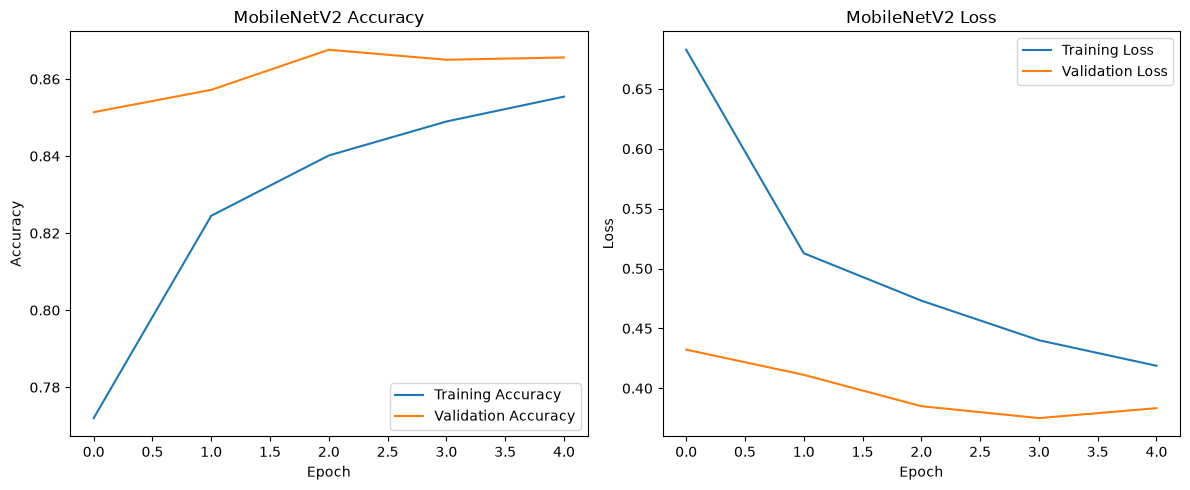

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
test_loss, test_accuracy = transfer_model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.8603 - loss: 0.4070
Test Loss: 0.4069591760635376
Test Accuracy: 0.8603000044822693
Test Accuracy Percentage: 86.03000044822693


In [23]:
# Get one batch from test dataset
for images, labels in test_dataset.take(1):
    test_images = images
    actual_labels = labels

# Generate predictions
predictions = transfer_model.predict(test_images)

# Convert probabilities into class predictions
predicted_labels = predictions.argmax(axis=1)

print("Actual Labels:", actual_labels.numpy()[:10])
print("Predicted Labels:", predicted_labels[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 804ms/step
Actual Labels: [3 8 8 0 6 6 1 6 3 1]
Predicted Labels: [3 8 8 0 6 6 1 6 3 1]


In [25]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

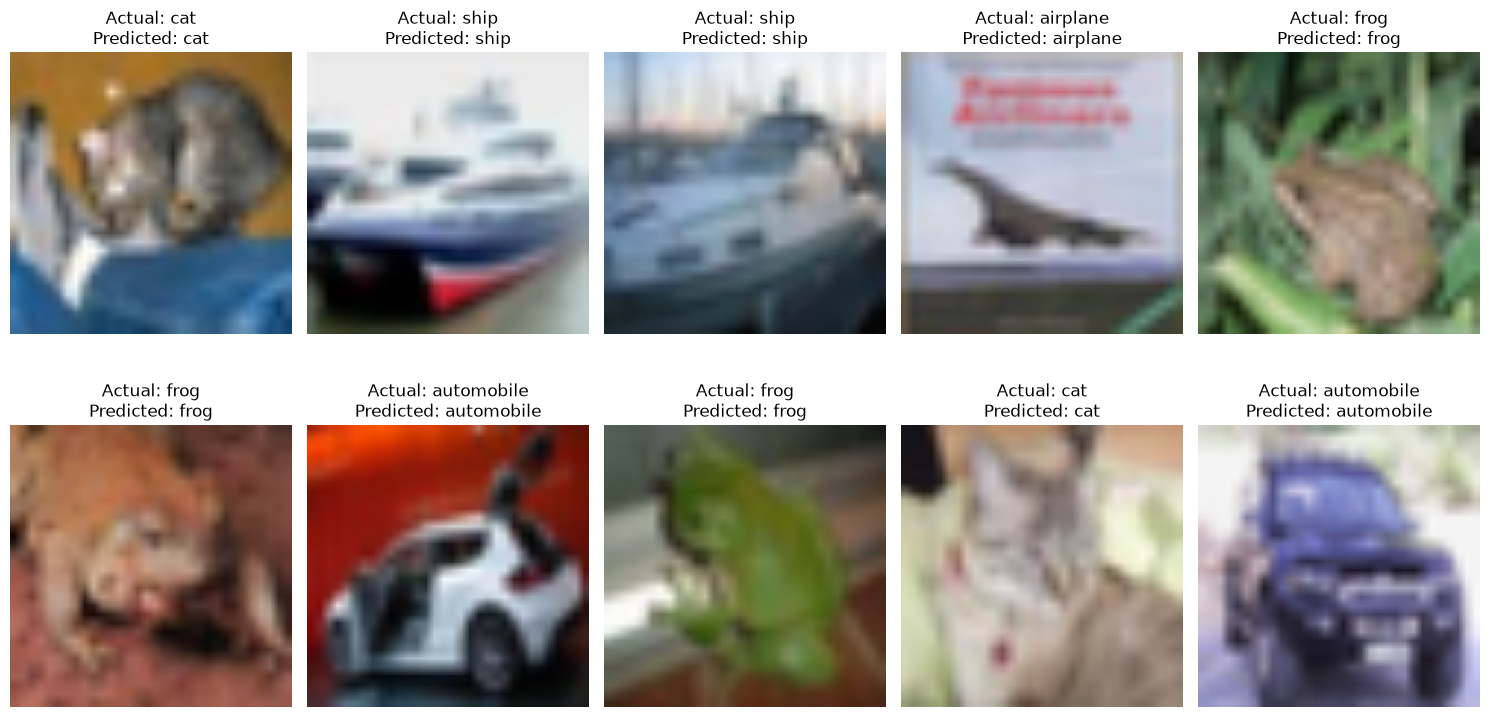

In [26]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(15, 8))

for i in range(10):
    # Convert image from [-1, 1] to [0, 1]
    image = (test_images[i].numpy() + 1.0) / 2.0

    actual = class_names[actual_labels[i].numpy()]
    predicted = class_names[predicted_labels[i]]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [27]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    probabilities = transfer_model.predict(images, verbose=0)

    predictions = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

Actual labels shape: (10000,)
Predicted labels shape: (10000,)


<Figure size 1000x800 with 0 Axes>

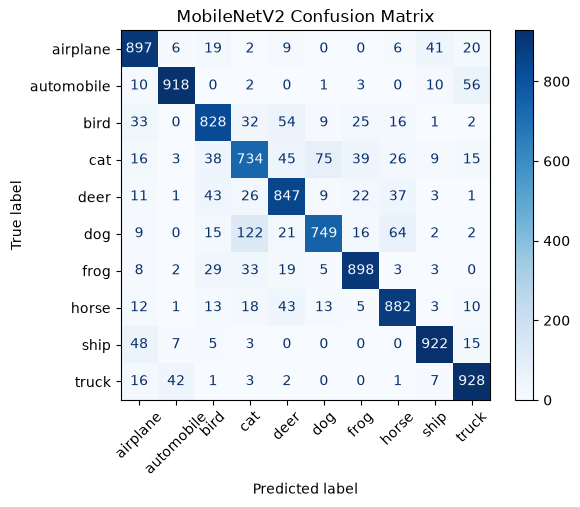

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

In [29]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

    airplane       0.85      0.90      0.87      1000
  automobile       0.94      0.92      0.93      1000
        bird       0.84      0.83      0.83      1000
         cat       0.75      0.73      0.74      1000
        deer       0.81      0.85      0.83      1000
         dog       0.87      0.75      0.80      1000
        frog       0.89      0.90      0.89      1000
       horse       0.85      0.88      0.87      1000
        ship       0.92      0.92      0.92      1000
       truck       0.88      0.93      0.91      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



### Generate comparison chart

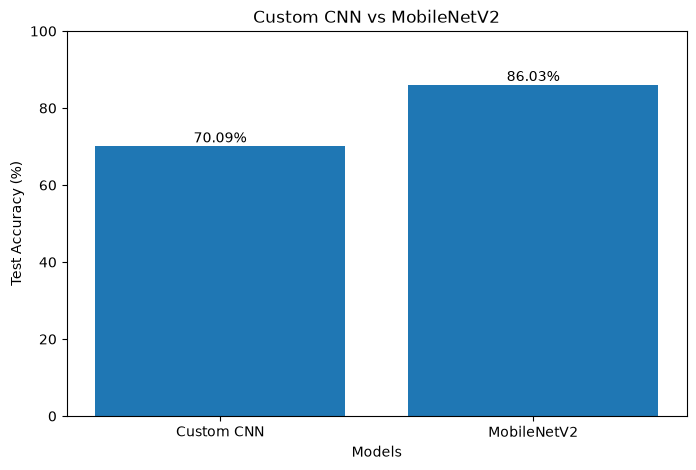

In [30]:
import matplotlib.pyplot as plt

model_names = ['Custom CNN', 'MobileNetV2']
accuracies = [70.09, 86.03]

plt.figure(figsize=(8, 5))

bars = plt.bar(model_names, accuracies)

plt.title('Custom CNN vs MobileNetV2')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f'{accuracy:.2f}%',
        ha='center'
    )

plt.show()

In [31]:
import pandas as pd

comparison = pd.DataFrame({
    'Model': ['Custom CNN', 'MobileNetV2'],
    'Test Accuracy': [70.09, 86.03],
    'Test Loss': [0.8914, 0.4070]
})

comparison.to_csv(
    'model_comparison.csv',
    index=False
)

print(comparison)

         Model  Test Accuracy  Test Loss
0   Custom CNN          70.09     0.8914
1  MobileNetV2          86.03     0.4070


### Task 5 – Model Analysis and Documentation


## Model Performance Analysis

Two deep learning models were developed and evaluated using the CIFAR-10 dataset: a custom Convolutional Neural Network (CNN) and a transfer learning model based on MobileNetV2.

### 1. Custom CNN

The custom CNN achieved a test accuracy of **70.09%** and a test loss of **0.8914**. The model was developed with 545,098 parameters and trained from scratch using CIFAR-10 images.

### 2. MobileNetV2

The MobileNetV2 transfer learning model achieved a test accuracy of **86.03%** and a test loss of **0.4070**. Its pretrained ImageNet weights provided useful visual feature representations, improving classification performance.

### 3. Model Comparison

MobileNetV2 outperformed the custom CNN by **15.94 percentage points** in test accuracy. It also achieved a lower test loss.

This demonstrates the benefit of transfer learning for image classification, particularly when using pretrained visual features.

### 4. Conclusion

Both models successfully performed CIFAR-10 image classification. However, MobileNetV2 achieved better test performance than the custom CNN. Therefore, MobileNetV2 is the preferred model for this project based on the observed test results.


In [34]:
transfer_model.save("mobilenetv2_model.keras")